In [2]:
import pandas as pd

df = pd.read_csv("../data/raw/2026_MCM_Problem_C_Data.csv")

df.head()

,celebrity_name,ballroom_partner,celebrity_industry,celebrity_homestate,celebrity_homecountry/region,celebrity_age_during_season,season,results,placement,week1_judge1_score,...,week9_judge3_score,week9_judge4_score,week10_judge1_score,week10_judge2_score,week10_judge3_score,week10_judge4_score,week11_judge1_score,week11_judge2_score,week11_judge3_score,week11_judge4_score
0,John O'Hurley,Charlotte Jorgensen,Actor/Actress,Maine,United States,50,1,2nd Place,2,7.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Kelly Monaco,Alec Mazo,Actor/Actress,Pennsylvania,United States,29,1,1st Place,1,5.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Evander Holyfield,Edyta Sliwinska,Athlete,Alabama,United States,42,1,Eliminated Week 3,5,5.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Rachel Hunter,Jonathan Roberts,Model,NaN,New Zealand,35,1,Eliminated Week 4,4,7.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Joey McIntyre,Ashly DelGrosso,Singer/Rapper,Massachusetts,United States,32,1,3rd Place,3,7.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
df.shape

df.columns.to_list()

df.info()

sorted(df['season'].dropna().unique())



<class 'pandas.DataFrame'>
RangeIndex: 421 entries, 0 to 420
Data columns (total 53 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   celebrity_name                421 non-null    str    
 1   ballroom_partner              421 non-null    str    
 2   celebrity_industry            421 non-null    str    
 3   celebrity_homestate           365 non-null    str    
 4   celebrity_homecountry/region  421 non-null    str    
 5   celebrity_age_during_season   421 non-null    int64  
 6   season                        421 non-null    int64  
 7   results                       421 non-null    str    
 8   placement                     421 non-null    int64  
 9   week1_judge1_score            421 non-null    float64
 10  week1_judge2_score            421 non-null    float64
 11  week1_judge3_score            407 non-null    float64
 12  week1_judge4_score            81 non-null     float64
 13  week2_judge1_sco

[np.int64(1),
 np.int64(2),
 np.int64(3),
 np.int64(4),
 np.int64(5),
 np.int64(6),
 np.int64(7),
 np.int64(8),
 np.int64(9),
 np.int64(10),
 np.int64(11),
 np.int64(12),
 np.int64(13),
 np.int64(14),
 np.int64(15),
 np.int64(16),
 np.int64(17),
 np.int64(18),
 np.int64(19),
 np.int64(20),
 np.int64(21),
 np.int64(22),
 np.int64(23),
 np.int64(24),
 np.int64(25),
 np.int64(26),
 np.int64(27),
 np.int64(28),
 np.int64(29),
 np.int64(30),
 np.int64(31),
 np.int64(32),
 np.int64(33),
 np.int64(34)]

In [4]:
missing_values = df.isnull().sum()

missing_values[missing_values > 0]

celebrity_homestate     56
week1_judge3_score      14
week1_judge4_score     340
week2_judge4_score     330
week3_judge4_score     293
week4_judge4_score     291
week5_judge1_score      10
week5_judge2_score      10
week5_judge3_score      10
week5_judge4_score     302
week6_judge1_score      10
week6_judge2_score      10
week6_judge3_score      10
week6_judge4_score     274
week7_judge1_score      16
week7_judge2_score      16
week7_judge3_score      16
week7_judge4_score     277
week8_judge1_score      16
week8_judge2_score      16
week8_judge3_score      16
week8_judge4_score     313
week9_judge1_score      26
week9_judge2_score      26
week9_judge3_score      26
week9_judge4_score     288
week10_judge1_score     52
week10_judge2_score     52
week10_judge3_score     52
week10_judge4_score    328
week11_judge1_score    302
week11_judge2_score    302
week11_judge3_score    302
week11_judge4_score    395
dtype: int64

In [5]:
score_columns = df.filter(regex=r'^week\d+_judge\d+_score$')

zero_counts = (score_columns == 0).sum()

zero_counts[zero_counts > 0]

week2_judge1_score      17
week2_judge2_score      17
week2_judge3_score      17
week2_judge4_score       4
week3_judge1_score      61
week3_judge2_score      61
week3_judge3_score      61
week3_judge4_score      21
week4_judge1_score      95
week4_judge2_score      95
week4_judge3_score      95
week4_judge4_score      27
week5_judge1_score     123
week5_judge2_score     123
week5_judge3_score     123
week5_judge4_score      32
week6_judge1_score     150
week6_judge2_score     150
week6_judge3_score     150
week6_judge4_score      48
week7_judge1_score     177
week7_judge2_score     177
week7_judge3_score     177
week7_judge4_score      60
week8_judge1_score     214
week8_judge2_score     214
week8_judge3_score     214
week8_judge4_score      53
week9_judge1_score     243
week9_judge2_score     243
week9_judge3_score     243
week9_judge4_score      77
week10_judge1_score    260
week10_judge2_score    260
week10_judge3_score    260
week10_judge4_score     65
week11_judge1_score     82
w

In [6]:
df[[
    'celebrity_name',
    'season',
    'results',
    'placement',
    "week1_judge1_score",
    "week2_judge1_score",
    "week3_judge1_score",
    "week4_judge1_score",
    "week5_judge1_score"
]].head(15)

,celebrity_name,season,results,placement,week1_judge1_score,week2_judge1_score,week3_judge1_score,week4_judge1_score,week5_judge1_score
0,John O'Hurley,1,2nd Place,2,7.0,8.0,9.0,7.0,9.0
1,Kelly Monaco,1,1st Place,1,5.0,5.0,6.0,9.0,8.5
2,Evander Holyfield,1,Eliminated Week 3,5,5.0,5.0,5.0,0.0,0.0
3,Rachel Hunter,1,Eliminated Week 4,4,7.0,8.0,8.0,7.0,0.0
4,Joey McIntyre,1,3rd Place,3,7.0,8.0,7.0,7.0,8.5
5,Trista Sutter,1,Eliminated Week 2,6,6.0,6.0,0.0,0.0,0.0
6,Tatum O'Neal,2,Eliminated Week 2,9,7.0,5.0,0.0,0.0,0.0
7,Tia Carrere,2,Eliminated Week 5,6,6.0,7.0,9.0,9.0,7.0
8,George Hamilton,2,Eliminated Week 6,5,7.0,8.0,7.0,7.0,8.0
9,Lisa Rinna,2,Eliminated Week 7,4,5.0,6.0,8.0,9.0,7.0


In [7]:
df_clean = df.copy()

score_cols = df_clean.filter(
    regex = r'week\d+_judge\d+_score$'
).columns

df_clean[score_cols] = df_clean[score_cols].replace(0,float('nan'))

In [8]:
(df_clean[score_cols] == 0).sum().sum()

np.int64(0)

In [9]:
df[score_cols].iloc[:5, :8]
df_clean[score_cols].iloc[:5, :8]

,week1_judge1_score,week1_judge2_score,week1_judge3_score,week1_judge4_score,week2_judge1_score,week2_judge2_score,week2_judge3_score,week2_judge4_score
0,7.0,7.0,6.0,NaN,8.0,9.0,9.0,NaN
1,5.0,4.0,4.0,NaN,5.0,6.0,6.0,NaN
2,5.0,7.0,6.0,NaN,5.0,4.0,5.0,NaN
3,7.0,6.0,7.0,NaN,8.0,8.0,8.0,NaN
4,7.0,7.0,6.0,NaN,8.0,7.0,6.0,NaN


In [10]:
df_clean.duplicated(
    subset = ['celebrity_name','season']
).sum()

np.int64(0)

### Data Cleaning: Weekly Judges' Scores

During the initial exploration, I found that zero scores were used to represent weeks after contestants had been eliminated. Since these zeros do not reflect actual performances, including them would incorrectly lower contestants' average scores.

To address this, I created a copy of the original dataset and replaced zeros in the weekly judges' score columns with missing values (`NaN`). This allows future calculations to exclude weeks when contestants did not perform while preserving the original dataset for reference.

In [11]:
df_long = df_clean.melt(
    id_vars = [
        "celebrity_name",
        "ballroom_partner",
        "celebrity_industry",
        "celebrity_age_during_season",
        "season",
        "results",
        "placement"
    ],
    value_vars = score_cols,
    var_name = 'week_judge',
    value_name = 'score'
    )

df_long.head()


,celebrity_name,ballroom_partner,celebrity_industry,celebrity_age_during_season,season,results,placement,week_judge,score
0,John O'Hurley,Charlotte Jorgensen,Actor/Actress,50,1,2nd Place,2,week1_judge1_score,7.0
1,Kelly Monaco,Alec Mazo,Actor/Actress,29,1,1st Place,1,week1_judge1_score,5.0
2,Evander Holyfield,Edyta Sliwinska,Athlete,42,1,Eliminated Week 3,5,week1_judge1_score,5.0
3,Rachel Hunter,Jonathan Roberts,Model,35,1,Eliminated Week 4,4,week1_judge1_score,7.0
4,Joey McIntyre,Ashly DelGrosso,Singer/Rapper,32,1,3rd Place,3,week1_judge1_score,7.0


In [12]:
df_long[['week','judge']] = (
    df_long['week_judge']
    .str.extract(r'week(\d+)_judge(\d+)_score')
    .astype(int)
)

df_long = df_long.drop(columns=['week_judge'])

df_long.head()

,celebrity_name,ballroom_partner,celebrity_industry,celebrity_age_during_season,season,results,placement,score,week,judge
0,John O'Hurley,Charlotte Jorgensen,Actor/Actress,50,1,2nd Place,2,7.0,1,1
1,Kelly Monaco,Alec Mazo,Actor/Actress,29,1,1st Place,1,5.0,1,1
2,Evander Holyfield,Edyta Sliwinska,Athlete,42,1,Eliminated Week 3,5,5.0,1,1
3,Rachel Hunter,Jonathan Roberts,Model,35,1,Eliminated Week 4,4,7.0,1,1
4,Joey McIntyre,Ashly DelGrosso,Singer/Rapper,32,1,3rd Place,3,7.0,1,1


In [13]:
df_long = df_long.dropna(subset=['score'])

df_long.shape

(9112, 10)

In [14]:
df_long.head(10)
df_long['score'].nunique()
df_long['score'].describe()

count    9112.000000
mean        7.918716
std         1.499010
min         2.000000
25%         7.000000
50%         8.000000
75%         9.000000
max        13.333300
Name: score, dtype: float64

In [15]:
contestant_avg = (
    df_long
    .groupby([
        'celebrity_name',
        'season',
        'ballroom_partner',
        'placement'
    ])['score']
    .mean()
    .reset_index(name='avg_score')
)
contestant_avg.head(10)

,celebrity_name,season,ballroom_partner,placement,avg_score
0,AJ McLean,29,Cheryl Burke,7,7.814807
1,Aaron Carter,9,Karina Smirnoff,5,8.604154
2,Adam Carolla,6,Julianne Hough,9,6.166667
3,Adam Rippon,26,Jenna Johnson,1,9.357143
4,Adrian Peterson,32,Britt Stewart,11,5.846154
5,Aiden Turner,10,Edyta Sliwinska,9,5.875000
6,Albert Reed,5,Anna Trebunskaya,11,7.000000
7,Alek Skarlatos,21,Lindsay Arnold,3,8.166664
8,Alexa PenaVega,21,Mark Ballas,6,8.549993
9,Alexandra Raisman,16,Mark Ballas,4,8.816667


In [16]:
high_scores = df_long[df_long['score'] > 10]

high_scores[[
    'celebrity_name',
    'season',
    'week',
    'judge',
    'score'
]].sort_values('score',ascending=False)

,celebrity_name,season,week,judge,score
9373,Nicole Scherzinger,10,6,3,13.3333
9422,Katherine Jenkins,14,6,3,13.3333
8580,Katherine Jenkins,14,6,1,13.3333
10278,Melissa Rycroft,15,7,1,13.3333
9412,William Levy,14,6,3,13.0000
...,...,...,...,...,...
9225,Xochitl Gomez,32,6,2,10.2500
7948,Wayne Brady,31,5,3,10.1250
7531,Heidi D'Amelio,31,5,2,10.1250
7527,Wayne Brady,31,5,2,10.1250


In [17]:

df_long[df_long["score"] > 10][
    ["celebrity_name", "season", "week", "judge", "score"]
].sort_values(["season", "week"])


,celebrity_name,season,week,judge,score
96,Joanna Krupa,9,1,1,11.3333
100,Aaron Carter,9,1,1,10.3333
101,Mya,9,1,1,11.3333
102,Donny Osmond,9,1,1,10.3333
517,Joanna Krupa,9,1,2,11.3333
...,...,...,...,...,...
14733,Whitney Leavitt,34,9,3,10.5000
14734,Dylan Efron,34,9,3,10.5000
15148,Robert Irwin,34,9,4,10.5000
15154,Whitney Leavitt,34,9,4,10.5000


In [18]:
# Look at scores above 10 in the original dataset
df_long[df_long["score"] > 10][
    ["celebrity_name", "season", "week", "judge", "score"]
]

,celebrity_name,season,week,judge,score
96,Joanna Krupa,9,1,1,11.3333
100,Aaron Carter,9,1,1,10.3333
101,Mya,9,1,1,11.3333
102,Donny Osmond,9,1,1,10.3333
517,Joanna Krupa,9,1,2,11.3333
...,...,...,...,...,...
16236,Carlos PenaVega,21,10,3,11.0000
16244,Bindi Irwin,21,10,3,10.5000
17032,Amber Riley,17,11,1,10.4444
17453,Amber Riley,17,11,2,10.4444


In [19]:
# Check how many judges contributed scores each week
judge_counts = (
    df_long
    .groupby(["celebrity_name", "season", "week"])["judge"]
    .nunique()
    .value_counts()
)

judge_counts

judge
3    1968
4     795
2      14
Name: count, dtype: int64

In [20]:

weekly_avg = (
    df_long
    .groupby([
        "celebrity_name",
        "season",
        "ballroom_partner",
        "placement",
        "week"
    ])
    .agg(
        avg_weekly_score=("score", "mean"),
        num_judges=("judge", "nunique")
    )
    .reset_index()
)

weekly_avg.head(10)


,celebrity_name,season,ballroom_partner,placement,week,avg_weekly_score,num_judges
0,AJ McLean,29,Cheryl Burke,7,1,6.000000,3
1,AJ McLean,29,Cheryl Burke,7,2,6.333333,3
2,AJ McLean,29,Cheryl Burke,7,3,7.000000,3
3,AJ McLean,29,Cheryl Burke,7,4,8.000000,3
4,AJ McLean,29,Cheryl Burke,7,5,8.000000,3
5,AJ McLean,29,Cheryl Burke,7,6,9.000000,3
6,AJ McLean,29,Cheryl Burke,7,7,8.666667,3
7,AJ McLean,29,Cheryl Burke,7,8,9.000000,3
8,AJ McLean,29,Cheryl Burke,7,9,8.333267,3
9,Aaron Carter,9,Karina Smirnoff,5,1,10.666633,3


In [21]:
contestant_avg = (
    weekly_avg
    .groupby([
        "celebrity_name",
        "season",
        "ballroom_partner",
        "placement"
    ])["avg_weekly_score"]
    .mean()
    .reset_index(name = 'avg_season_score')
)

contestant_avg.head(10)

,celebrity_name,season,ballroom_partner,placement,avg_season_score
0,AJ McLean,29,Cheryl Burke,7,7.814807
1,Aaron Carter,9,Karina Smirnoff,5,8.604154
2,Adam Carolla,6,Julianne Hough,9,6.166667
3,Adam Rippon,26,Jenna Johnson,1,9.291667
4,Adrian Peterson,32,Britt Stewart,11,5.875000
5,Aiden Turner,10,Edyta Sliwinska,9,5.875000
6,Albert Reed,5,Anna Trebunskaya,11,7.000000
7,Alek Skarlatos,21,Lindsay Arnold,3,8.212118
8,Alexa PenaVega,21,Mark Ballas,6,8.518511
9,Alexandra Raisman,16,Mark Ballas,4,8.816667


In [22]:
contestant_avg['score_rank'] = (
    contestant_avg
    .groupby('season')['avg_season_score']
    .rank(ascending=False, method='min')
)
contestant_avg[
    contestant_avg['season'] == 34
].sort_values('score_rank')

,celebrity_name,season,ballroom_partner,placement,avg_season_score,score_rank
414,Whitney Leavitt,34,Mark Ballas,6,8.970833,1.0
342,Robert Irwin,34,Witney Carson (Xoshitl Gomez week 9),1,8.838382,2.0
12,Alix Earle,34,Val Chmerkovskiy (Joey Graziadei week 9),2,8.791667,3.0
202,Jordan Chiles,34,Ezra Sosa (Apolo Anton Ohno week 9),3,8.588382,4.0
115,Dylan Efron,34,Daniella Karagach (Rumer Willis week 9),4,8.404036,5.0
116,Elaine Hendrix,34,Alan Bersten (Rashad Jennings week 9),5,8.185600,6.0
94,Danielle Fishel,34,Pasha Pashkov,8,7.572917,7.0
177,Jen Affleck,34,Jan Ravnik,9,7.297619,8.0
149,Hilaria Baldwin,34,Gleb Savchenko,11,7.250000,9.0
355,Scott Hoying,34,Rylee Arnold,10,6.638889,10.0


### Understanding the Scoring System

After reviewing the dataset documentation, I found that DWTS scoring has varied throughout the show's history. Some weeks included multiple dances, team performances, or bonus points, which explains why certain recorded scores exceed the usual maximum of 10.

The documentation also confirmed that zero scores represent weeks after contestants were eliminated, while missing values may indicate an absent fourth judge or weeks when a season did not air.

To account for differences in the number of judges, I calculated each contestant's average score per week before calculating their overall season average. I retained scores above 10 because they reflect adjustments included in the original dataset. 

These differences in scoring formats will be considered when comparing contestants and seasons.

# 4. Exploratory Data Analysis



## 4.1 Judges' Score vs. Final Placements

This analysis examines whether contestants with the highest
average judges' scores also achieve the highest final
placements.

I will compare contestants' scoring rankings with their
actual competition results to identify differences
between judges' evaluations and final outcomes.



### 4.1.1 Statistical Analysis: Spearman's Rank Correlation

To evaluate the relationship between judges' scores and final
placements, I will use Spearman's Rank Correlation.

This test measures the strength and direction of the
relationship between two ranked variables.


In [25]:
%pip install scipy

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.4/62.4 kB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20.5/20.5 MB 8.1 MB/s eta 0:00:0000:0100:01m

[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [26]:
from scipy.stats import spearmanr

In [31]:
season_correlations = []

for season, group in contestant_avg.groupby('season'):
    if len(group) >= 3:
        rho, p_val = spearmanr(
            group['score_rank'],
            group['placement']
        )

        season_correlations.append({
            'season': season,
            'correlation': rho,
            'p_value': p_val
        })

season_correlations = pd.DataFrame(season_correlations)

season_correlations

,season,correlation,p_value
0,1,0.657143,1.561749e-01
1,2,0.686933,2.820556e-02
2,3,0.890909,2.334582e-04
3,4,0.683373,2.043986e-02
4,5,0.783217,2.586215e-03
5,6,0.951049,2.038425e-06
6,7,0.873626,9.528897e-05
7,8,0.835165,3.802081e-04
8,9,0.878587,7.521206e-06
9,10,0.890909,2.334582e-04


### Interpretation of Spearman's Rank Correlation

The Spearman's Rank Correlation analysis showed a strong positive relationship between judges' scoring rankings and contestants' final placements across all 34 seasons of Dancing with the Stars.

Correlation coefficients ranged from approximately 0.657 to 0.978, indicating that contestants with higher average judges' scores generally finished in better positions.

Season 23 had the strongest relationship (ρ = 0.978), while Season 1 had the weakest (ρ = 0.657). Season 27 also had a relatively low correlation (ρ = 0.659), making it an interesting season to investigate further.

At the 0.05 significance level, 33 of the 34 seasons had statistically significant correlations before adjusting for multiple comparisons.

Overall, these findings suggest that judges' scores are strongly associated with final competition placements. However, the relationship is not perfect, indicating that other factors, potentially including audience voting, may contribute to the final results.


### 4.1.3 Highest-Scoring Contestants vs. Winners

### Code and results

In [33]:
top_scorers = contestant_avg[
    contestant_avg['score_rank'] == 1
].copy()

top_scorers['won'] = top_scorers['placement'] == 1

top_scorers[
    ~top_scorers['won']
][[
    'season',
    'celebrity_name',
    'ballroom_partner',
    'avg_season_score',
    'placement'
]].sort_values('season')

,season,celebrity_name,ballroom_partner,avg_season_score,placement
196,1,John O'Hurley,Charlotte Jorgensen,8.055556,2
370,2,Stacy Keibler,Tony Dovolani,9.173604,3
258,3,Mario Lopez,Karina Smirnoff,8.955553,2
274,5,Mel B,Maksim Chmerkoskiy,9.077773,2
135,8,Gilles Marini,Cheryl Burke,9.227273,2
298,9,Mya,Dmitry Chaplin,9.477767,2
70,12,Chelsea Kane,Mark Ballas,8.655553,3
338,13,Ricki Lake,Derek Hough,8.866660,3
215,14,Katherine Jenkins,Mark Ballas,9.516663,2
420,16,Zendaya,Valentin Chmerkovskiy,9.099993,2


In [42]:

top_scorers.groupby("season").size().value_counts()
top_scorer_win_rate = (
    top_scorers["won"].mean() * 100
)

print(f"Top scorer win rate: {top_scorer_win_rate:.1f}%")



Top scorer win rate: 41.2%


In [44]:
season_wins = (
    top_scorers
    .groupby('season')['won']
    .any()
)

win_counts = season_wins.value_counts()

print('Season analyzed:', len(season_wins))
print('Top scorer won:', season_wins.sum())
print('Top scorer did not win:', (~season_wins).sum())
print(f'Win rate: {season_wins.mean() * 100:.1f}%')

Season analyzed: 34
Top scorer won: 14
Top scorer did not win: 20
Win rate: 41.2%


### 4.1.4 Visualizing Top Scorer Win Rates

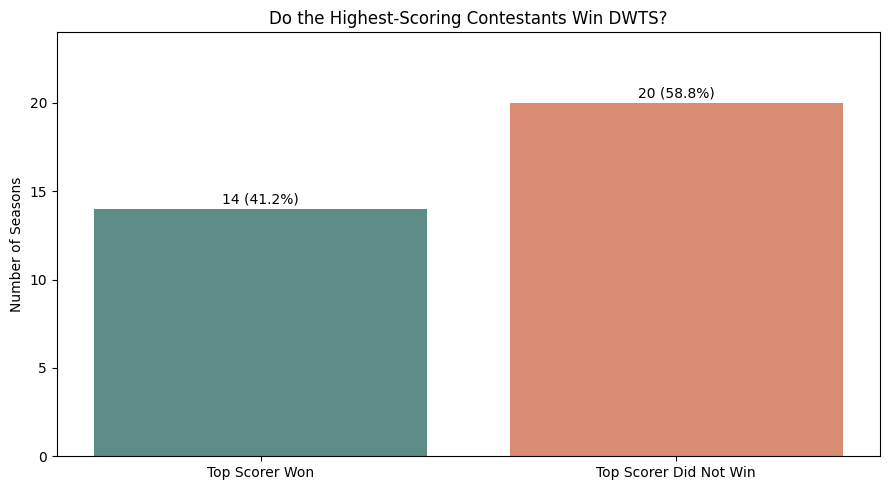

In [48]:
import matplotlib.pyplot as plt

outcomes = [
    season_wins.sum(),
    (~season_wins).sum()
]
labels = ['Top Scorer Won','Top Scorer Did Not Win']

plt.figure(figsize=(9,5))

bars = plt.bar(
    labels,
    outcomes,
    color = ["#5B8C85", "#D98C73"]
)
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        height + 0.3,
        f"{int(height)} ({height / len(season_wins) * 100:.1f}%)",
        ha='center'
    )
plt.title("Do the Highest-Scoring Contestants Win DWTS?")
plt.ylabel("Number of Seasons")
plt.ylim(0, max(outcomes) + 4)
plt.tight_layout()
plt.show()

### Findings and Interpretation

Across 34 seasons of Dancing with the Stars, the contestant with the highest average judges' score did not win in 20 seasons (58.8%). In the remaining 14 seasons (41.2%), the highest-scoring contestant won, assuming no ties for the top scoring rank.

These findings are interesting when compared with the Spearman correlation analysis, which showed a strong positive relationship between judges' scores and final placements. Although higher-scoring contestants generally finish in better positions, having the highest average score does not guarantee winning the competition.

Several seasons had noticeable differences between scoring rankings and final placements. Season 27 was particularly interesting because Juan Pablo Di Pace had the highest average score but finished fifth, while Bobby Bones won despite ranking eighth in average judges' scores.

Overall, these findings suggest that judges' scores are an important part of competition success, but they do not fully explain the final outcomes.

### 4.1.5 Case Study: Season 27 and Bobby Bones


Season 27 had one of the weakest correlations between judges' scores and final placements (ρ = 0.659). This season was also controversial because Bobby Bones won despite consistently receiving lower judges' scores than several other contestants.

To investigate this further, I compared contestants' average scoring rankings with their actual final placements.

In [38]:
season_27 = contestant_avg[
    contestant_avg['season'] == 27
].sort_values('score_rank')

contestant_avg["rank_difference"] = (
    contestant_avg["score_rank"] - contestant_avg["placement"]
)

season_27[[
    'celebrity_name',
    'ballroom_partner',
    'avg_season_score',
    'score_rank',
    'placement',
    'rank_difference'
]]

,celebrity_name,ballroom_partner,avg_season_score,score_rank,placement,rank_difference
208,Juan Pablo Di Pace,Cheryl Burke,9.125000,1.0,5,-4.0
289,Milo Manheim,Witney Carson,9.092593,2.0,2,0.0
10,Alexis Ren,Alan Bersten,8.833333,3.0,4,-1.0
126,Evanna Lynch,Keo Motsepe,8.685185,4.0,3,1.0
388,Tinashe,Brandon Armstrong,8.500000,5.0,10,-5.0
100,DeMarcus Ware,Lindsay Arnold,8.238095,6.0,7,-1.0
266,Mary Lou Retton,Sasha Farber,7.888889,7.0,9,-2.0
44,Bobby Bones,Sharna Burgess,7.462963,8.0,1,7.0
198,John Schneider,Emma Slater,7.214286,9.0,8,1.0
301,Nancy McKeon,Valentin Chmerkovskiy,6.888889,10.0,11,-1.0


### Findings and Interpretation

Bobby Bones ranked eighth out of 13 contestants with an average judges' score of 7.46 but finished in first place, resulting in a ranking difference of +7. Meanwhile, Juan Pablo Di Pace had the highest average score of 9.13 but finished fifth.

These results show a noticeable difference between judges' scoring rankings and the final competition results. Although audience voting likely played a role, the dataset does not include actual voting totals, so its exact influence cannot be measured.

Season 27 demonstrates that having the highest judges' scores does not necessarily guarantee success in the competition.


## 4.2 Celebrity Background and Competition Success




This analysis examines whether a celebrity's professional
background is associated with their success on Dancing
with the Stars.

I will compare contestants across different industries
and use a Chi-Square Test of Independence to determine
whether industry and competition success are associated.


### 4.2.1 Industry Classification

In [50]:
df_clean['celebrity_industry'].value_counts()

celebrity_industry
Actor/Actress               128
Athlete                      95
TV Personality               67
Singer/Rapper                61
Model                        17
Comedian                     12
Social Media Personality      8
Racing Driver                 4
Radio Personality             4
Entrepreneur                  4
News Anchor                   3
Politician                    3
Sports Broadcaster            2
Beauty Pagent                 1
Magician                      1
Astronaut                     1
Fashion Designer              1
Motivational Speaker          1
Military                      1
Journalist                    1
Musician                      1
Producer                      1
Fitness Instructor            1
Con artist                    1
Conservationist               1
Social media personality      1
Name: count, dtype: int64

In [52]:
industry_pct = (
    df_clean['celebrity_industry']
    .value_counts(normalize=True) * 100
)

industry_pct.round(2)

celebrity_industry
Actor/Actress               30.40
Athlete                     22.57
TV Personality              15.91
Singer/Rapper               14.49
Model                        4.04
Comedian                     2.85
Social Media Personality     1.90
Racing Driver                0.95
Radio Personality            0.95
Entrepreneur                 0.95
News Anchor                  0.71
Politician                   0.71
Sports Broadcaster           0.48
Beauty Pagent                0.24
Magician                     0.24
Astronaut                    0.24
Fashion Designer             0.24
Motivational Speaker         0.24
Military                     0.24
Journalist                   0.24
Musician                     0.24
Producer                     0.24
Fitness Instructor           0.24
Con artist                   0.24
Conservationist              0.24
Social media personality     0.24
Name: proportion, dtype: float64

In [53]:
industry_df = df_clean.copy()

major_industries = [
    'Actor/Actress',
    'Athlete',
    'TV Personality',
    'Singer/Rapper'
]

industry_df['industry_group'] = (
    industry_df['celebrity_industry']
    .where(
        industry_df['celebrity_industry'].isin(major_industries),
        'Other'
    )
)

industry_df['industry_group'].value_counts()

industry_group
Actor/Actress     128
Athlete            95
Other              70
TV Personality     67
Singer/Rapper      61
Name: count, dtype: int64

In [54]:
industry_df['top_three'] = (
    industry_df['placement'] <= 3
)

industry_df['top_three'].value_counts()

top_three
False    319
True     102
Name: count, dtype: int64

In [55]:
contingency_table = pd.crosstab(
    industry_df['industry_group'],
    industry_df['top_three']
)

contingency_table

top_three,False,True
industry_group,,
Actor/Actress,99,29
Athlete,68,27
Other,54,16
Singer/Rapper,45,16
TV Personality,53,14


### Industry Classification and Competition Success

The original dataset contained 27 celebrity industry labels, with several categories representing only a small number of contestants.

To make the comparison more manageable, I kept the four largest industry categories separate and grouped the remaining categories into an "Other" category.

For this analysis, I defined competition success as finishing in the top three. I then created a contingency table to compare top-three finishes across industry groups.

This table will be used to conduct a Chi-Square Test of Independence to determine whether celebrity industry and competition success are statistically associated.

### 4.2.2 Chi-Square Test of Independence

### Hypotheses

**Null Hypothesis (H₀):** Celebrity industry and finishing in the top three are independent. There is no association between a contestant's professional background and their likelihood of finishing in the top three.

**Alternative Hypothesis (H₁):** Celebrity industry and finishing in the top three are associated. At least one industry group has a different top-three finish rate.

The significance level for this test is α = 0.05.

In [61]:
from scipy.stats import chi2_contingency

chi2, p_value, dof, expected = chi2_contingency(
    contingency_table
)

print(f'Chi-Square Statistic: {chi2:.4f}')
print(f'P-value: {p_value:.4f}')
print(f"Degree of Freedom: {dof}")

Chi-Square Statistic: 1.6921
P-value: 0.7921
Degree of Freedom: 4


In [62]:
expected_df =  pd.DataFrame(
    expected,
    index=contingency_table.index,
    columns=contingency_table.columns
)

display(expected_df.round(2))

print('Minimum expected frequency:', expected.min())
print('Expected cells below 5:', (expected < 5).sum())

top_three,False,True
industry_group,,
Actor/Actress,96.99,31.01
Athlete,71.98,23.02
Other,53.04,16.96
Singer/Rapper,46.22,14.78
TV Personality,50.77,16.23


Minimum expected frequency: 14.779097387173397
Expected cells below 5: 0


In [63]:
alpha = 0.05

if p_value < alpha:
    print('Reject the null hypothesis.')
    print('There is statistically significant evidence of an association between celebrity industry and top-three placement.')
else:
    print('Fail to reject the null hypothesis.')
    print('There is insufficient statistical evidence of an association between celebrity industry and top-three placement.')

Fail to reject the null hypothesis.
There is insufficient statistical evidence of an association between celebrity industry and top-three placement.


In [64]:
import numpy as np

n = contingency_table.to_numpy().sum()

cramers_v = np.sqrt(
    chi2 / (n * min(contingency_table.shape[0] -1,
    contingency_table.shape[1] - 1))
)
print(f"Chi-Square Statistic: {chi2:.4f}")
print(f"P-value: {p_value:.4f}")
print(f"Cramér's V: {cramers_v:.4f}")
print(f"Minimum Expected Frequency: {expected.min():.2f}")


Chi-Square Statistic: 1.6921
P-value: 0.7921
Cramér's V: 0.0634
Minimum Expected Frequency: 14.78


### Findings and Interpretation

The Chi-Square Test of Independence did not find a statistically significant association between celebrity industry and finishing in the top three on Dancing with the Stars (χ²(4) = 1.692, p = 0.792).

Since the p-value was greater than the significance level of 0.05, I failed to reject the null hypothesis.

Cramér's V was approximately 0.063, indicating a very weak association between the two variables.

These results suggest that celebrity industry alone may not be a strong indicator of whether a contestant finishes in the top three. However, the results do not prove that professional background has no influence on competition outcomes.

The analysis also grouped less common industries into an "Other" category, which may hide differences between individual professions. Additionally, differences in season formats and contestant groups should be considered when interpreting the findings.

### 4.2.3 Top-Three Finish Rates by Industry

In [66]:
industry_success = (
    industry_df
    .groupby('industry_group')['top_three']
    .agg(['count','sum','mean'])
    .reset_index()
)

industry_success.columns = [
    'industry',
    "total_contestants",
    "top_three_finishes",
    "success_rate"
]



industry_success['success_rate'] *= 100


industry_success = industry_success.sort_values(
    'success_rate',
    ascending=False
)

industry_success.round(2)

,industry,total_contestants,top_three_finishes,success_rate
1,Athlete,95,27,28.42
3,Singer/Rapper,61,16,26.23
2,Other,70,16,22.86
0,Actor/Actress,128,29,22.66
4,TV Personality,67,14,20.90


### Findings and Interpretation

Athletes had the highest top-three finish rate at 28.42%, followed by singers and rappers at 26.23%. TV personalities had the lowest rate at 20.90%.

Although there were some differences between industry groups, the Chi-Square test did not find a statistically significant association between celebrity industry and top-three placement (p = 0.7921).

These findings suggest that professional background alone may not be a strong indicator of competition success. However, other factors and differences between seasons may also influence the results.